<a href="https://colab.research.google.com/github/srijansinha331-eng/EDA.NUMPY/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Upload train.csv from your computer
uploaded = files.upload()
df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Saving train.csv to train.csv
Dataset shape: (1460, 10)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Id           1460 non-null   int64  
 1   MSSubClass   1460 non-null   int64  
 2   MSZoning     1460 non-null   object 
 3   LotFrontage  1201 non-null   float64
 4   LotArea      1460 non-null   int64  
 5   Street       1460 non-null   object 
 6   Alley        91 non-null     object 
 7   LotShape     1460 non-null   object 
 8   LandContour  1460 non-null   object 
 9   Utilities    1460 non-null   object 
dtypes: float64(1), int64(3), object(6)
memory usage: 114.2+ KB


In [ ]:
# Count missing values and calculate percentages
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing[missing["Missing Count"] > 0])
print("Number of columns with missing values:", (df.isna().sum() > 0).sum())

,Missing Count,Missing Percentage
Alley,1369,93.77
LotFrontage,259,17.74


Number of columns with missing values: 2


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for column, order in ordinal_map.items():
    if column in df.columns:
        df[column] = pd.Categorical(df[column], categories=order, ordered=True)

# Create a simple variable summary
variable_summary = pd.DataFrame({
    "Column": df.columns,
    "Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values,
    "Example Values": [df[c].dropna().unique()[:5].tolist() for c in df.columns]
})
display(variable_summary)

print("OverallQual is numerical in the dataset but represents an ordered quality rating.")

,Column,Type,Unique Values,Example Values
0,Id,int64,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,int64,15,"[60, 20, 70, 50, 190]"
2,MSZoning,object,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250, 9550, 14260]"
5,Street,object,2,"[Pave, Grvl]"
6,Alley,object,2,"[Grvl, Pave]"
7,LotShape,object,4,"[Reg, IR1, IR2, IR3]"
8,LandContour,object,4,"[Lvl, Bnk, Low, HLS]"
9,Utilities,object,2,"[AllPub, NoSeWa]"


OverallQual is numerical in the dataset but represents an ordered quality rating.


In [ ]:
display(df.describe().T)

target_columns = ["SalePrice", "GrLivArea", "LotArea"]
available_columns = [col for col in target_columns if col in df.columns]

if not available_columns:
    print(f"None of the requested columns {target_columns} are present in this dataset.")

for column in available_columns:
    series = df[column].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    print(f"\nStatistics for {column}:")
    print("Mean:", series.mean())
    print("Median:", series.median())
    print("Mode:", series.mode().iloc[0] if not series.mode().empty else "N/A")
    print("Standard deviation:", series.std())
    print("Variance:", series.var())
    print("Range:", series.max() - series.min())
    print("IQR:", q3 - q1)
    print("Skewness:", series.skew())
    print("Kurtosis:", series.kurt())

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0



Statistics for LotArea:
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [ ]:
target_cats = ["Neighborhood", "HouseStyle", "MSZoning", "Street", "Alley", "LotShape", "LandContour", "Utilities"]
available_cats = [col for col in target_cats if col in df.columns]

if not available_cats:
    print("None of the target categorical columns are present in this dataset.")

for column in available_cats:
    print(f"\nValue counts for {column}:")
    display(df[column].value_counts(dropna=False))
    modes = df[column].mode().tolist()
    print("Mode:", modes)


Value counts for MSZoning:


,count
MSZoning,
RL,1151
RM,218
FV,65
RH,16
C (all),10


Mode: ['RL']

Value counts for Street:


,count
Street,
Pave,1454
Grvl,6


Mode: ['Pave']

Value counts for Alley:


,count
Alley,
NaN,1369
Grvl,50
Pave,41


... (3 outputs left out)

,count
LandContour,
Lvl,1311
Bnk,63
HLS,50
Low,36


Mode: ['Lvl']

Value counts for Utilities:


,count
Utilities,
AllPub,1459
NoSeWa,1


Mode: ['AllPub']


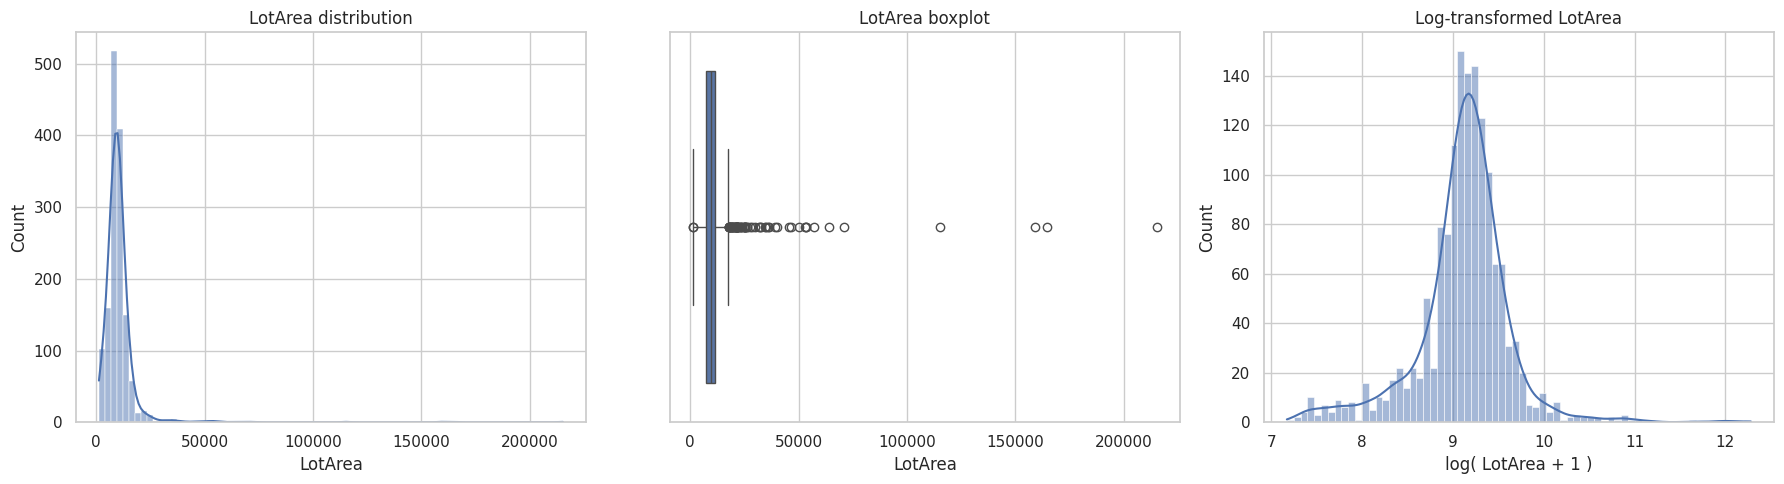

LotArea skewness: 12.207687851233496
Log LotArea skewness: -0.13740448122837784


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df["LotArea"], kde=True, ax=axes[0])
axes[0].set_title("LotArea distribution")
sns.boxplot(x=df["LotArea"], ax=axes[1])
axes[1].set_title("LotArea boxplot")
sns.histplot(np.log1p(df["LotArea"]), kde=True, ax=axes[2])
axes[2].set_title("Log-transformed LotArea")
axes[2].set_xlabel("log( LotArea + 1 )")
plt.tight_layout()
plt.show()

print("LotArea skewness:", df["LotArea"].skew())
print("Log LotArea skewness:", np.log1p(df["LotArea"]).skew())

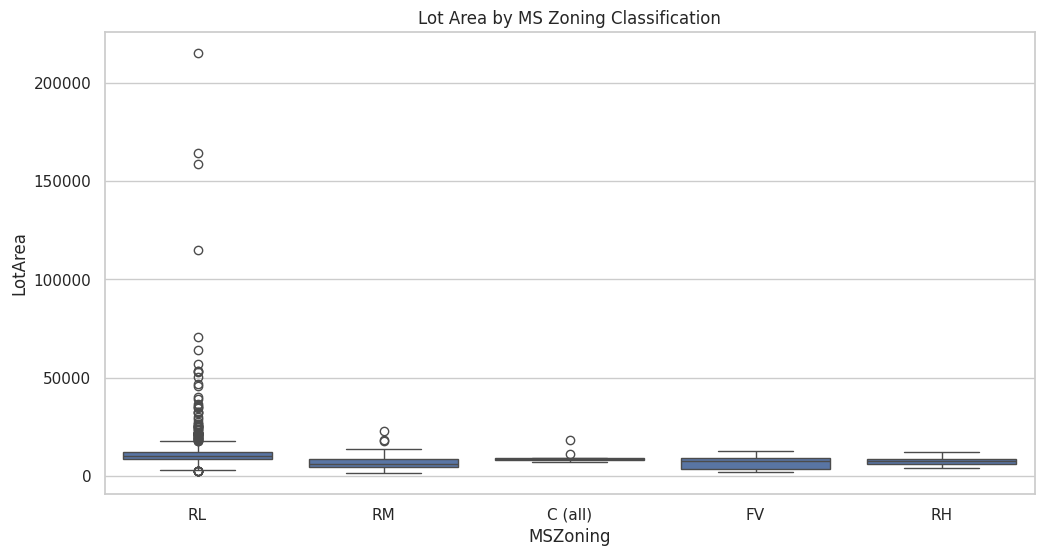

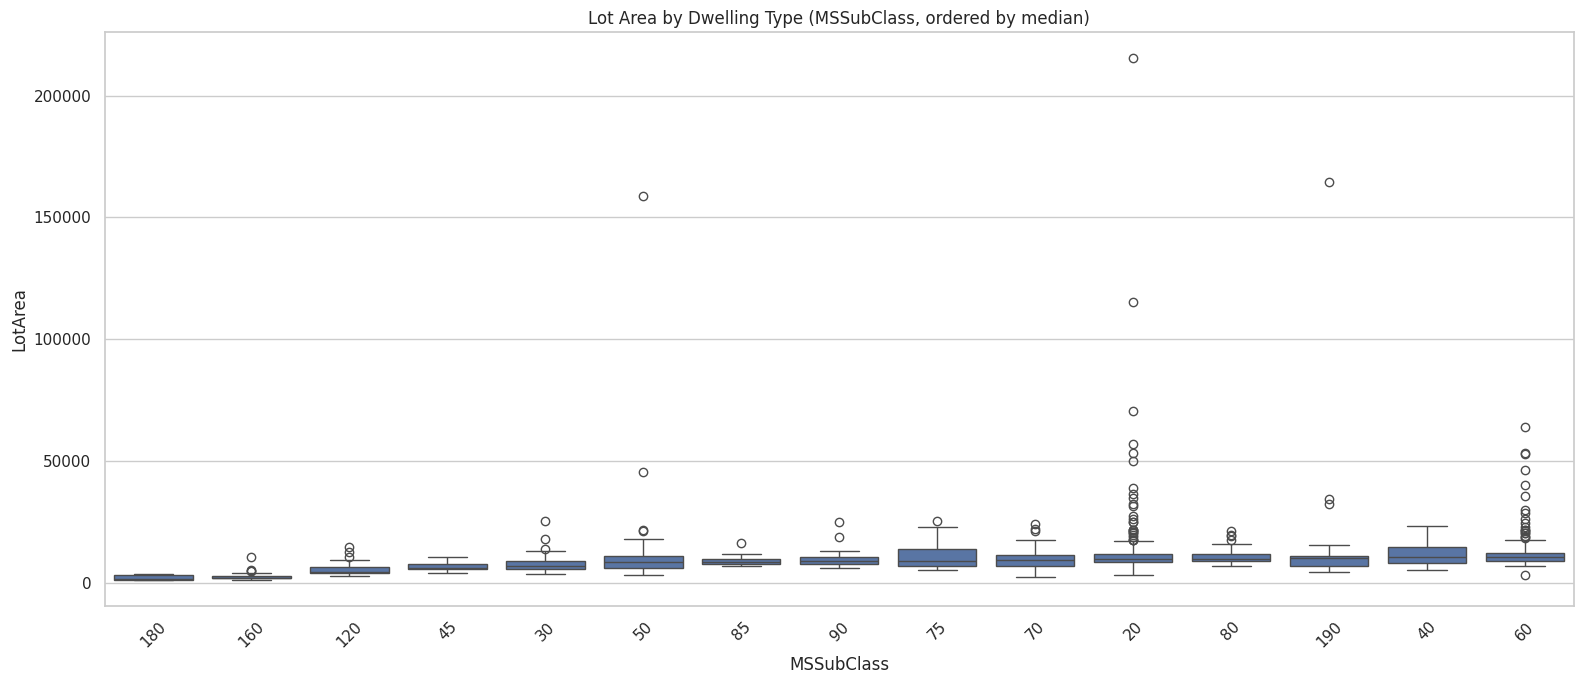

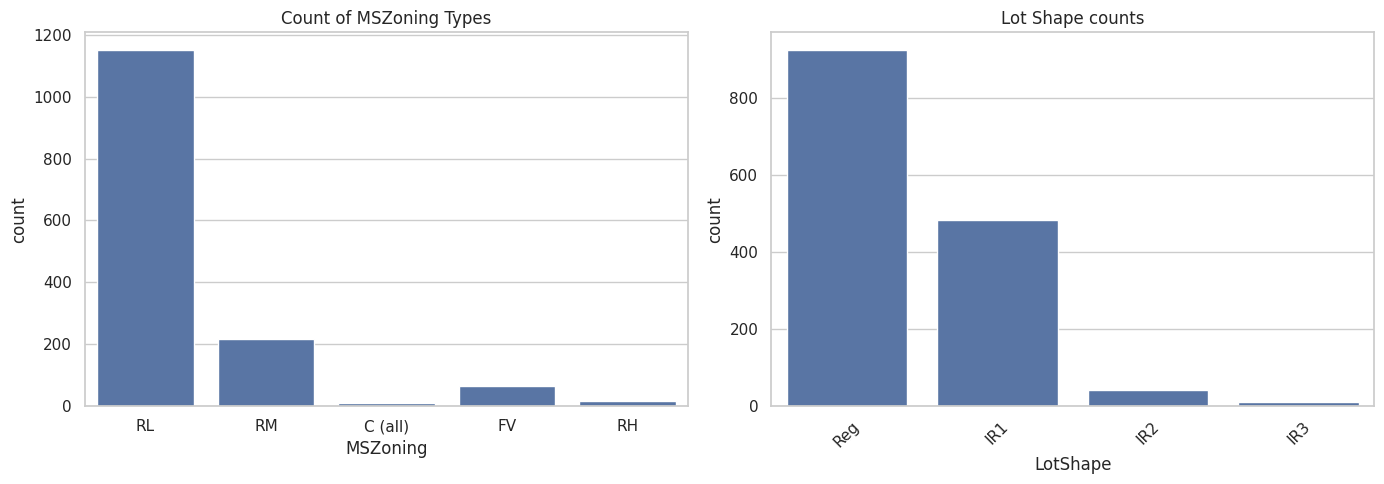

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Boxplot of LotArea by MSZoning (if columns exist)
if "MSZoning" in df.columns and "LotArea" in df.columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x="MSZoning", y="LotArea")
    plt.title("Lot Area by MS Zoning Classification")
    plt.show()

# 2. Ordered Boxplot of LotArea by MSSubClass (if columns exist)
if "MSSubClass" in df.columns and "LotArea" in df.columns:
    subclass_order = df.groupby("MSSubClass")["LotArea"].median().sort_values().index
    plt.figure(figsize=(16, 7))
    sns.boxplot(data=df, x="MSSubClass", y="LotArea", order=subclass_order)
    plt.xticks(rotation=45)
    plt.title("Lot Area by Dwelling Type (MSSubClass, ordered by median)")
    plt.tight_layout()
    plt.show()

# 3. Countplots of MSZoning and LotShape
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if "MSZoning" in df.columns:
    sns.countplot(data=df, x="MSZoning", ax=axes[0])
    axes[0].set_title("Count of MSZoning Types")

if "LotShape" in df.columns:
    sns.countplot(data=df, x="LotShape", ax=axes[1])
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].set_title("Lot Shape counts")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Filter to available numeric columns, excluding 'Id'
numeric_cols = [col for col in df.select_dtypes(include=np.number).columns if col != 'Id']
num_df = df[numeric_cols]

cov_matrix = num_df.cov()
corr_matrix = num_df.corr()

print("Covariance Matrix for available numerical features:")
display(cov_matrix)

print("\nCorrelation Matrix for available numerical features:")
display(corr_matrix)

# Let's inspect the correlation of other variables with 'LotArea' specifically, since it is our primary numerical variable of interest
if "LotArea" in corr_matrix.columns:
    top_corr_lotarea = corr_matrix["LotArea"].drop("LotArea").sort_values(
        key=lambda values: values.abs(), ascending=False
    )
    print("\nNumerical features correlated with LotArea:")
    display(top_corr_lotarea.to_frame("Correlation with LotArea"))


Covariance Matrix for available numerical features:


,MSSubClass,LotFrontage,LotArea
MSSubClass,1789.338306,-404.439075,-5.901742e+04
LotFrontage,-404.439075,589.749169,8.199814e+04
LotArea,-59017.418634,81998.138404,9.962565e+07



Correlation Matrix for available numerical features:


,MSSubClass,LotFrontage,LotArea
MSSubClass,1.000000,-0.386347,-0.139781
LotFrontage,-0.386347,1.000000,0.426095
LotArea,-0.139781,0.426095,1.000000



Numerical features correlated with LotArea:


,Correlation with LotArea
LotFrontage,0.426095
MSSubClass,-0.139781


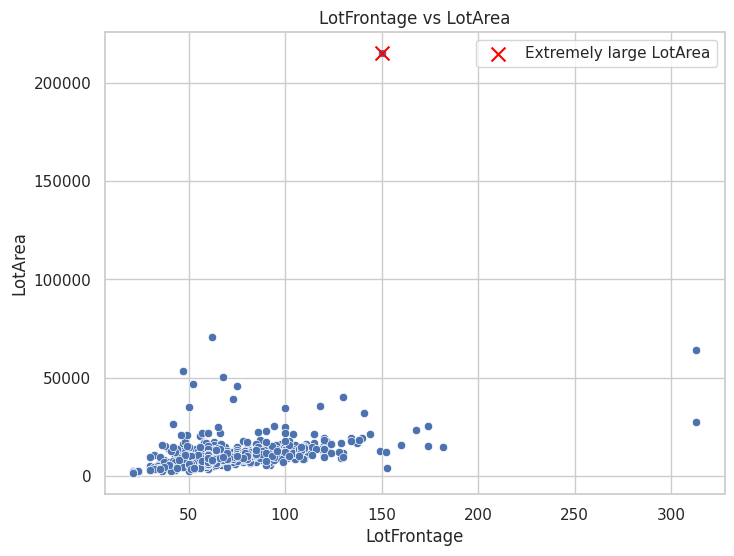

Plotting pairwise distributions for available numerical features:


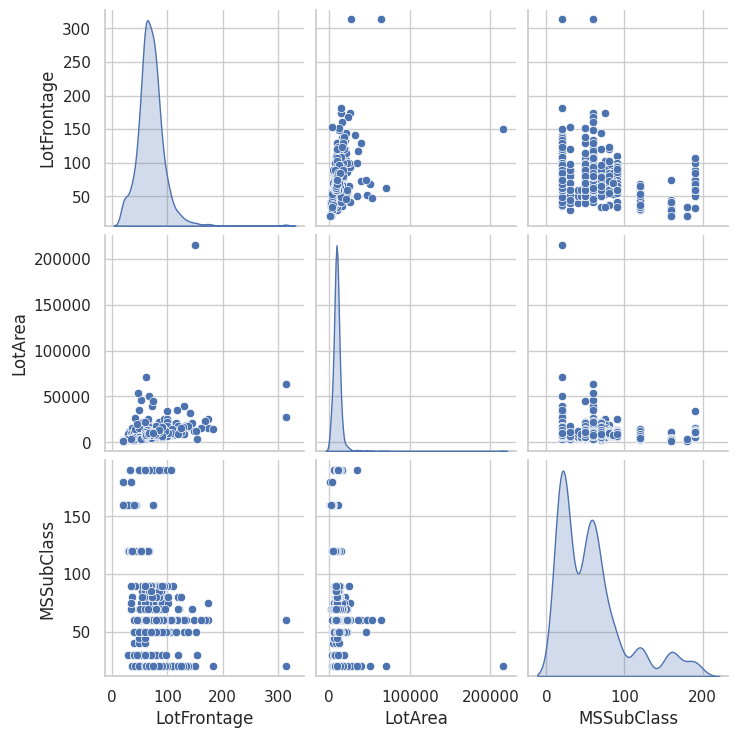

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Filter to available numeric columns (excluding 'Id')
available_numeric = [col for col in ["LotFrontage", "LotArea", "MSSubClass"] if col in df.columns]

if len(available_numeric) >= 2:
    # 1. Scatter plot of the two main physical continuous dimensions: LotFrontage vs LotArea
    if "LotFrontage" in available_numeric and "LotArea" in available_numeric:
        plt.figure(figsize=(8, 6))
        sns.scatterplot(data=df, x="LotFrontage", y="LotArea")

        # Highlight potential outliers with very large LotArea but standard LotFrontage
        unusual = df[(df["LotArea"] > 100000) & (df["LotFrontage"].notna())]
        if not unusual.empty:
            plt.scatter(unusual["LotFrontage"], unusual["LotArea"], marker="x", s=100, color='red', label="Extremely large LotArea")
            plt.legend()

        plt.title("LotFrontage vs LotArea")
        plt.show()

    # 2. Pairwise plot of all available numeric columns
    print("Plotting pairwise distributions for available numerical features:")
    sns.pairplot(df[available_numeric].dropna(), diag_kind="kde")
    plt.show()
else:
    print("Not enough numerical columns available to perform relational plotting.")

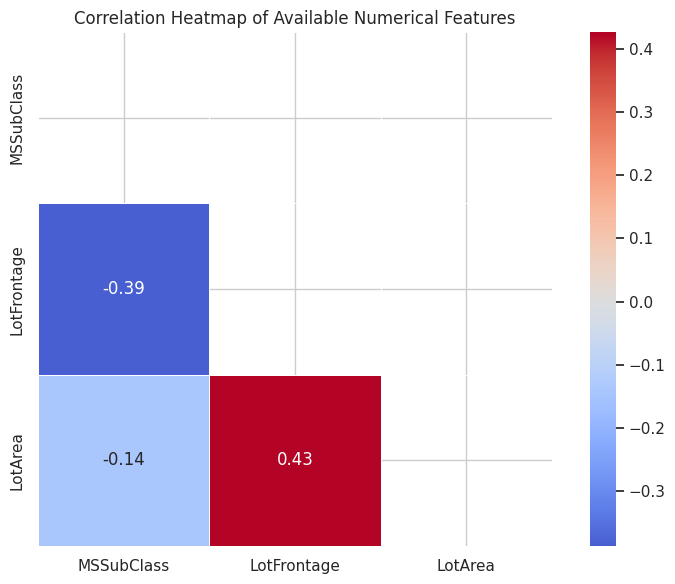

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify available numeric columns (excluding 'Id')
available_numeric = [col for col in ["MSSubClass", "LotFrontage", "LotArea"] if col in df.columns]

if len(available_numeric) >= 2:
    # Calculate the correlation matrix for available features
    corr_matrix_subset = df[available_numeric].corr()

    # Generate a mask for the upper triangle
    mask = np.triu(np.ones_like(corr_matrix_subset, dtype=bool))

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        corr_matrix_subset,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        mask=mask,
        square=True,
        linewidths=.5
    )
    plt.title("Correlation Heatmap of Available Numerical Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns available to plot a heatmap.")

In [ ]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold]

# Dynamic selection of continuous numeric columns actually present in the dataset
target_cols = [col for col in ["LotArea", "LotFrontage"] if col in df.columns]

for column in target_cols:
    # Drop NA values for accurate outlier computation
    series_clean = df[column].dropna()
    a = iqr_outliers(series_clean)
    b = zscore_outliers(series_clean)
    print(f"\n{column}:")
    print("IQR outlier count:", len(a))
    print("Z-score outlier count:", len(b))
    print("Overlap between methods:", len(set(a.index).intersection(set(b.index))))


LotArea:
IQR outlier count: 69
Z-score outlier count: 13
Overlap between methods: 13

LotFrontage:
IQR outlier count: 88
Z-score outlier count: 12
Overlap between methods: 12


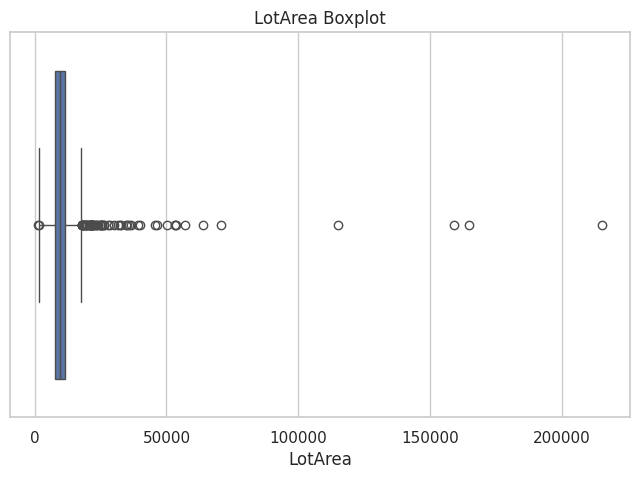

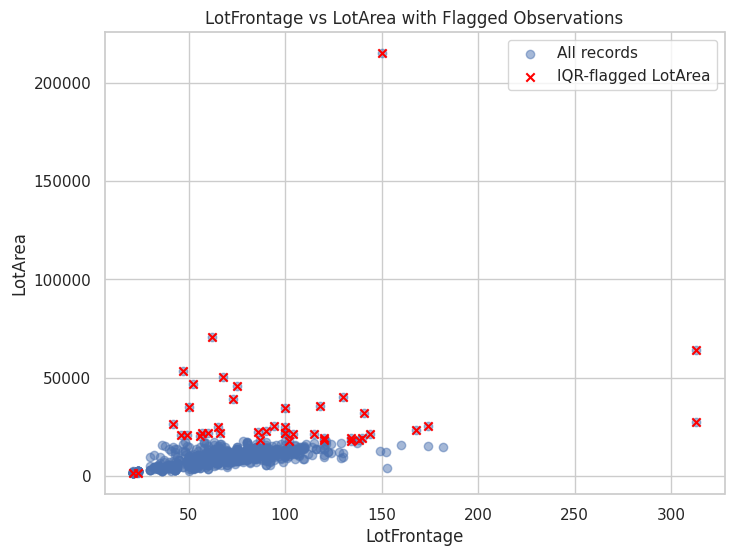


Reviewing top flagged outlier records based on LotArea:


,LotArea,LotFrontage,MSZoning,LotShape
313,215245,150.0,RL,IR3
335,164660,NaN,RL,IR1
249,159000,NaN,RL,IR2
706,115149,NaN,RL,IR2
451,70761,62.0,RL,IR1
1298,63887,313.0,RL,IR3
1396,57200,NaN,RL,IR1
769,53504,47.0,RL,IR2
457,53227,NaN,RL,IR1
384,53107,NaN,RL,IR2


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Dynamic fallback using LotArea as the primary variable of interest
primary_col = "LotArea"
secondary_col = "LotFrontage" if "LotFrontage" in df.columns else None

if primary_col in df.columns:
    # 1. Plot boxplot of the primary column
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=df[primary_col])
    plt.title(f"{primary_col} Boxplot")
    plt.show()

    # Calculate IQR outliers for the primary column
    flagged_indices = iqr_outliers(df[primary_col]).index
    iqr_flag = df.index.isin(flagged_indices)

    # 2. Scatter plot against the secondary column if available
    if secondary_col:
        plt.figure(figsize=(8, 6))
        plt.scatter(df[secondary_col], df[primary_col], alpha=0.5, label="All records")
        plt.scatter(df.loc[iqr_flag, secondary_col], df.loc[iqr_flag, primary_col],
                    label=f"IQR-flagged {primary_col}", marker="x", color="red")
        plt.xlabel(secondary_col)
        plt.ylabel(primary_col)
        plt.title(f"{secondary_col} vs {primary_col} with Flagged Observations")
        plt.legend()
        plt.show()

    # 3. Review flagged records dynamically with available columns
    flagged = df.loc[flagged_indices]
    available_show_cols = [col for col in [primary_col, "LotFrontage", "MSZoning", "LotShape"] if col in df.columns]

    print(f"\nReviewing top flagged outlier records based on {primary_col}:")
    display(flagged[available_show_cols].sort_values(primary_col, ascending=False).head(10))
else:
    print(f"Column '{primary_col}' is not present in the dataset.")

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
# This dataset typically has no duplicate rows, but inspect before removing.
df_clean = df.drop_duplicates().copy()
print("Shape after duplicate removal:", df_clean.shape)

# Check whitespace/casing in object columns
for column in df_clean.select_dtypes(include="object").columns:
    values = df_clean[column].dropna()
    suspicious = values[values.str.strip().str.lower() != values].unique()
    if len(suspicious):
        print("Potential formatting issues in", column, ":", suspicious[:10])

Duplicate rows: 0
Shape after duplicate removal: (1460, 10)
Potential formatting issues in MSZoning : ['RL' 'RM' 'C (all)' 'FV' 'RH']
Potential formatting issues in Street : ['Pave' 'Grvl']
Potential formatting issues in Alley : ['Grvl' 'Pave']
Potential formatting issues in LotShape : ['Reg' 'IR1' 'IR2' 'IR3']
Potential formatting issues in LandContour : ['Lvl' 'Bnk' 'Low' 'HLS']
Potential formatting issues in Utilities : ['AllPub' 'NoSeWa']


In [ ]:
import numpy as np
import pandas as pd

# For these columns, missing values commonly mean the feature is absent.
absence_columns = ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType",
                   "GarageFinish", "GarageQual", "GarageCond", "BsmtQual",
                   "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
                   "MasVnrType"]
for column in absence_columns:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].fillna("None")

# LotFrontage: fill using neighborhood median if available, otherwise use overall median.
if "LotFrontage" in df_clean.columns:
    if "Neighborhood" in df_clean.columns:
        df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(
            lambda group: group.fillna(group.median())
        )
    df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(df_clean["LotFrontage"].median())

# Remaining numeric missing values: use median.
for column in df_clean.select_dtypes(include=np.number).columns:
    if df_clean[column].isna().any():
        df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# Remaining categorical missing values: use "Unknown" rather than guessing.
for column in df_clean.select_dtypes(include=["object", "category"]).columns:
    if df_clean[column].isna().any():
        df_clean[column] = df_clean[column].astype("object").fillna("Unknown")

remaining_missing = df_clean.isna().sum().sort_values(ascending=False)
display(remaining_missing[remaining_missing > 0])
print("Cleaned shape:", df_clean.shape)

,0


Cleaned shape: (1460, 10)


In [ ]:
# Check for impossible or suspicious values
if "YearBuilt" in df_clean.columns and "YrSold" in df_clean.columns:
    display(df_clean[df_clean["YearBuilt"] > df_clean["YrSold"]][["YearBuilt", "YrSold"]])

area_columns = ["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea"]
for column in area_columns:
    if column in df_clean.columns:
        print(column, "negative values:", (df_clean[column] < 0).sum())

LotArea negative values: 0


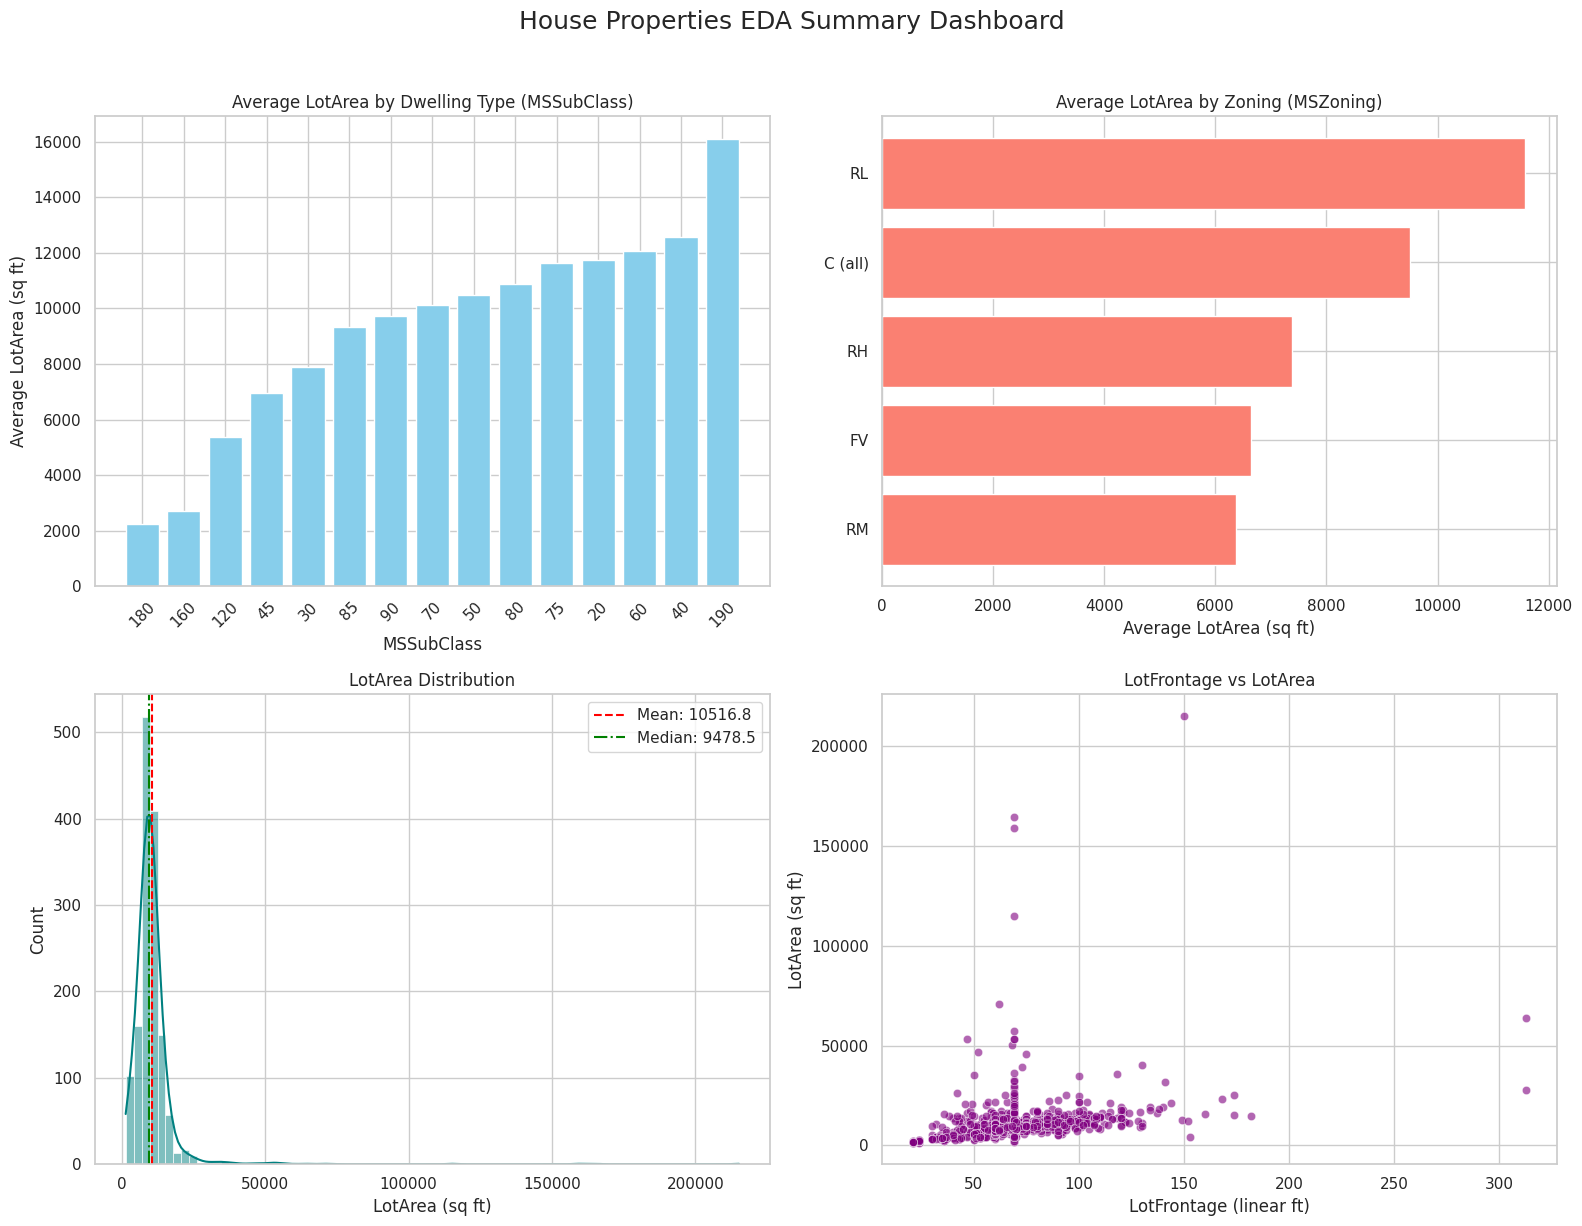

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Average LotArea by MSSubClass (Dwelling Type)
if "MSSubClass" in df_clean.columns and "LotArea" in df_clean.columns:
    subclass_avg = df_clean.groupby("MSSubClass", observed=True)["LotArea"].mean().sort_values()
    axes[0, 0].bar(subclass_avg.index.astype(str), subclass_avg.values, color="skyblue")
    axes[0, 0].set_title("Average LotArea by Dwelling Type (MSSubClass)")
    axes[0, 0].set_xlabel("MSSubClass")
    axes[0, 0].set_ylabel("Average LotArea (sq ft)")
    axes[0, 0].tick_params(axis='x', rotation=45)
else:
    axes[0, 0].text(0.5, 0.5, "MSSubClass or LotArea Missing", ha='center', va='center')

# Panel 2: Average LotArea by MSZoning
if "MSZoning" in df_clean.columns and "LotArea" in df_clean.columns:
    zoning_avg = df_clean.groupby("MSZoning", observed=True)["LotArea"].mean().sort_values()
    axes[0, 1].barh(zoning_avg.index, zoning_avg.values, color="salmon")
    axes[0, 1].set_title("Average LotArea by Zoning (MSZoning)")
    axes[0, 1].set_xlabel("Average LotArea (sq ft)")
else:
    axes[0, 1].text(0.5, 0.5, "MSZoning or LotArea Missing", ha='center', va='center')

# Panel 3: LotArea Distribution
if "LotArea" in df_clean.columns:
    sns.histplot(df_clean["LotArea"], kde=True, ax=axes[1, 0], color="teal")
    axes[1, 0].axvline(df_clean["LotArea"].mean(), color="red", linestyle="--", label=f"Mean: {df_clean['LotArea'].mean():.1f}")
    axes[1, 0].axvline(df_clean["LotArea"].median(), color="green", linestyle="-.", label=f"Median: {df_clean['LotArea'].median():.1f}")
    axes[1, 0].set_title("LotArea Distribution")
    axes[1, 0].set_xlabel("LotArea (sq ft)")
    axes[1, 0].legend()
else:
    axes[1, 0].text(0.5, 0.5, "LotArea Column Missing", ha='center', va='center')

# Panel 4: LotFrontage vs LotArea
if "LotFrontage" in df_clean.columns and "LotArea" in df_clean.columns:
    sns.scatterplot(data=df_clean, x="LotFrontage", y="LotArea", alpha=0.6, ax=axes[1, 1], color="purple")
    axes[1, 1].set_title("LotFrontage vs LotArea")
    axes[1, 1].set_xlabel("LotFrontage (linear ft)")
    axes[1, 1].set_ylabel("LotArea (sq ft)")
else:
    axes[1, 1].text(0.5, 0.5, "LotFrontage or LotArea Missing", ha='center', va='center')

fig.suptitle("House Properties EDA Summary Dashboard", fontsize=18, y=1.02)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
df_clean.to_csv("ames_housing_cleaned.csv", index=False)
print("Saved: ames_housing_cleaned.csv and eda_dashboard.png")

# Download files from Colab
files.download("ames_housing_cleaned.csv")
files.download("eda_dashboard.png")

Saved: ames_housing_cleaned.csv and eda_dashboard.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>